In [1]:
# Milestone 1

In [2]:
import sys
import random
import warnings

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Display / plotting defaults
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scipy       :", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("statsmodels :", statsmodels.__version__)
print("\nSetup OK. Seed =", SEED)

Python      : 3.13.16
numpy       : 2.1.3
pandas      : 2.2.3
scipy       : 1.16.3
scikit-learn: 1.6.1
matplotlib  : 3.10.0
seaborn     : 0.13.2
statsmodels : 0.15.0

Setup OK. Seed = 42


In [3]:
!pip install -q kagglehub

import kagglehub, os

path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Downloaded to:", path)

for f in os.listdir(path):
    size_mb = os.path.getsize(os.path.join(path, f)) / 1e6
    print(f"{f}  ({size_mb:.1f} MB)")

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Downloaded to: /kaggle/input/creditcardfraud
creditcard.csv  (150.8 MB)


In [4]:
# Milestone 2

In [5]:
import os
import pandas as pd

# 'path' comes from Cell 1.3. Re-define it here in case the session restarted.
path = "/kaggle/input/creditcardfraud"
df = pd.read_csv(os.path.join(path, "creditcard.csv"))

print("Shape (rows, columns):", df.shape)
print("\nColumns:", list(df.columns))
df.head()

Shape (rows, columns): (284807, 31)

Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [6]:
print("Missing values per column (total):", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("\nData types:")
print(df.dtypes.value_counts())
print("\nMemory usage: %.1f MB" % (df.memory_usage(deep=True).sum() / 1e6))

Missing values per column (total): 0
Duplicate rows: 1081

Data types:
float64    30
int64       1
Name: count, dtype: int64

Memory usage: 70.6 MB


In [7]:
counts = df["Class"].value_counts()
pct = df["Class"].value_counts(normalize=True) * 100

summary = pd.DataFrame({"count": counts, "percent": pct.round(4)})
summary.index = ["Normal (0)", "Fraud (1)"]
print(summary)
print(f"\nImbalance ratio: 1 fraud per {counts[0] / counts[1]:.0f} normal transactions")

             count  percent
Normal (0)  284315  99.8273
Fraud (1)      492   0.1727

Imbalance ratio: 1 fraud per 578 normal transactions


In [8]:
# Milestone 3

In [9]:
print(df[["Time", "Amount"]].describe().T)

print("\nAmount by class:")
print(df.groupby("Class")["Amount"].describe())

print("\nTime span covered: %.1f hours" % (df["Time"].max() / 3600))

              count        mean         std    min         25%         50%  \
Time   284,807.0000 94,813.8596 47,488.1460 0.0000 54,201.5000 84,692.0000   
Amount 284,807.0000     88.3496    250.1201 0.0000      5.6000     22.0000   

                75%          max  
Time   139,320.5000 172,792.0000  
Amount      77.1650  25,691.1600  

Amount by class:
             count     mean      std    min    25%     50%      75%  \
Class                                                                 
0     284,315.0000  88.2910 250.1051 0.0000 5.6500 22.0000  77.0500   
1         492.0000 122.2113 256.6833 0.0000 1.0000  9.2500 105.8900   

              max  
Class              
0     25,691.1600  
1      2,125.8700  

Time span covered: 48.0 hours


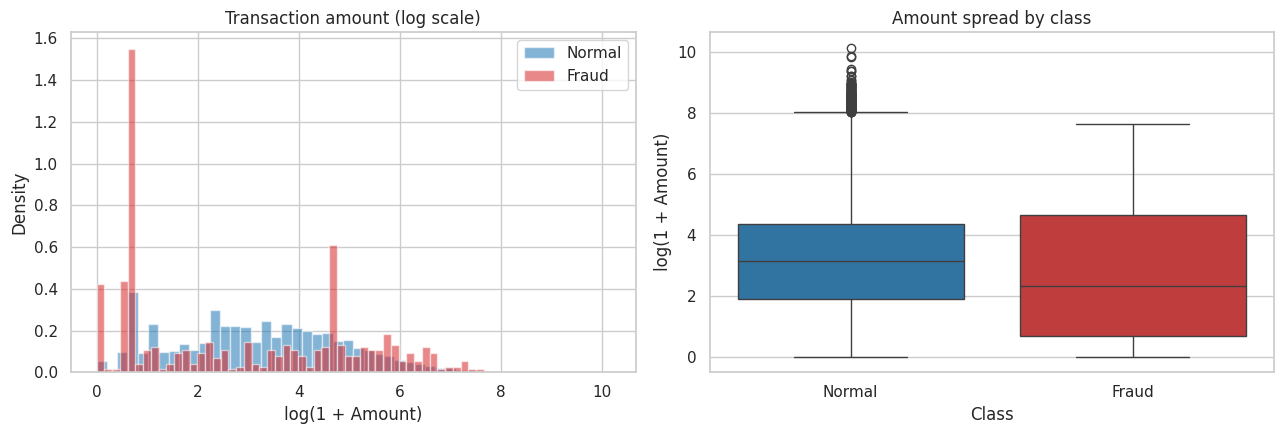

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: log-scaled histogram (density), so the two classes are comparable
for cls, label, color in [(0, "Normal", "tab:blue"), (1, "Fraud", "tab:red")]:
    axes[0].hist(np.log1p(df.loc[df["Class"] == cls, "Amount"]),
                 bins=50, density=True, alpha=0.55, label=label, color=color)
axes[0].set_xlabel("log(1 + Amount)")
axes[0].set_ylabel("Density")
axes[0].set_title("Transaction amount (log scale)")
axes[0].legend()

# Right: boxplot on log scale
sns.boxplot(data=df, x="Class", y=np.log1p(df["Amount"]), ax=axes[1],
            palette=["tab:blue", "tab:red"])
axes[1].set_xticklabels(["Normal", "Fraud"])
axes[1].set_ylabel("log(1 + Amount)")
axes[1].set_title("Amount spread by class")

plt.tight_layout()
plt.show()

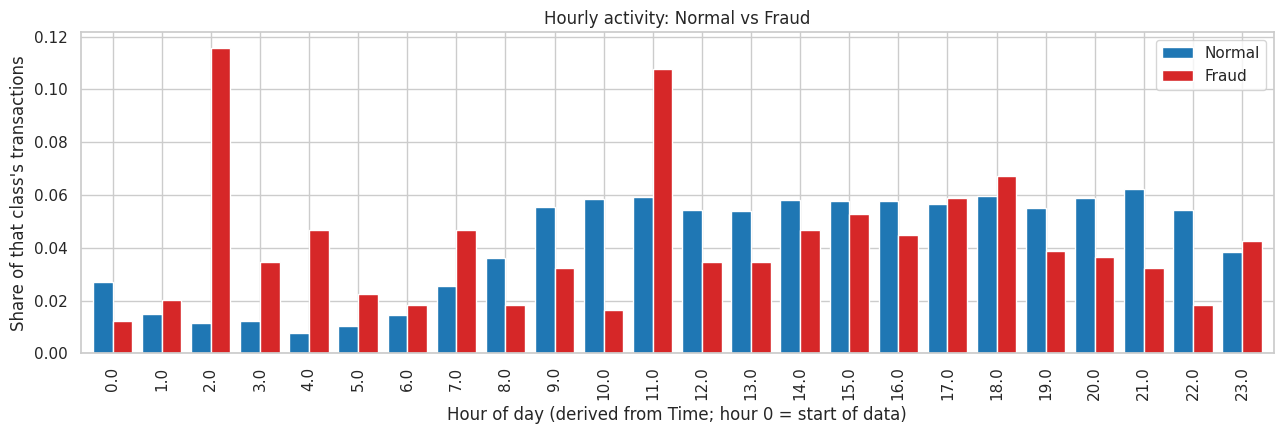

Fraud rate per hour (%):
Hour
0.0000    0.0780
1.0000    0.2370
2.0000    1.7130
3.0000    0.4870
4.0000    1.0410
5.0000    0.3680
6.0000    0.2190
7.0000    0.3180
8.0000    0.0880
9.0000    0.1010
10.0000   0.0480
11.0000   0.3140
12.0000   0.1100
13.0000   0.1110
14.0000   0.1390
15.0000   0.1580
16.0000   0.1340
17.0000   0.1790
18.0000   0.1940
19.0000   0.1210
20.0000   0.1070
21.0000   0.0900
22.0000   0.0580
23.0000   0.1920


In [11]:
df_eda = df.copy()   # copy so the original df stays untouched
df_eda["Hour"] = (df_eda["Time"] // 3600) % 24

hourly = (df_eda.groupby(["Hour", "Class"]).size()
                .unstack(fill_value=0))
share = hourly / hourly.sum()      # each class's share of its own total

ax = share.plot(kind="bar", figsize=(13, 4.5), color=["tab:blue", "tab:red"],
                width=0.8)
ax.set_xlabel("Hour of day (derived from Time; hour 0 = start of data)")
ax.set_ylabel("Share of that class's transactions")
ax.set_title("Hourly activity: Normal vs Fraud")
ax.legend(["Normal", "Fraud"])
plt.tight_layout()
plt.show()

print("Fraud rate per hour (%):")
print((hourly[1] / hourly.sum(axis=1) * 100).round(3).to_string())

feature  KS_stat  corr_with_Class
    V14   0.8428          -0.3025
    V10   0.8043          -0.2169
    V12   0.7839          -0.2606
     V4   0.7664           0.1334
    V11   0.7561           0.1549
    V17   0.7452          -0.3265
     V3   0.7037          -0.1930
    V16   0.6865          -0.1965
     V7   0.6606          -0.1873
     V2   0.6332           0.0913


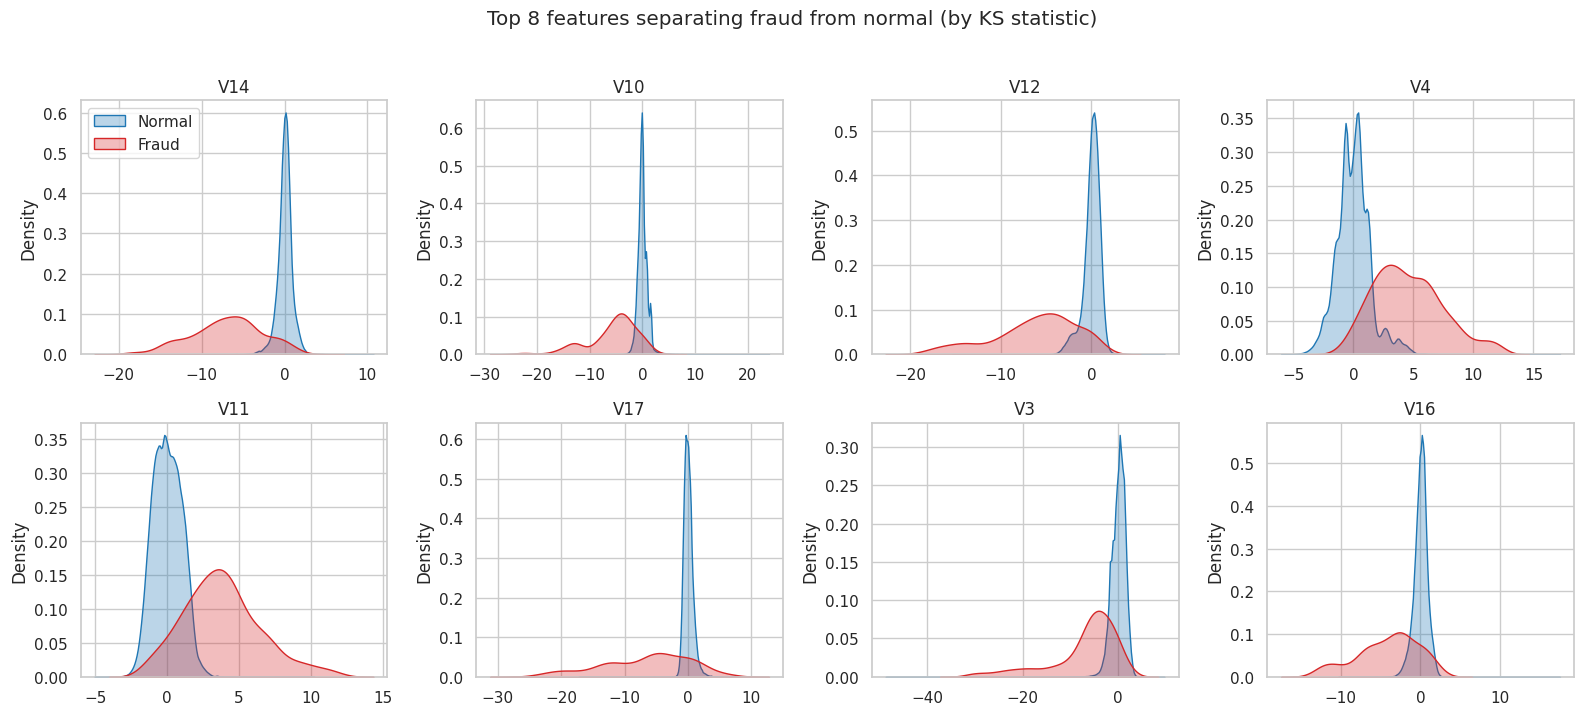

In [12]:
from scipy.stats import ks_2samp

v_cols = [c for c in df.columns if c.startswith("V")]
fraud  = df[df["Class"] == 1]
normal = df[df["Class"] == 0]

rows = []
for c in v_cols:
    ks = ks_2samp(fraud[c], normal[c]).statistic   # 0 = same distribution, 1 = fully separated
    corr = df[c].corr(df["Class"])
    rows.append((c, ks, corr))

sep = (pd.DataFrame(rows, columns=["feature", "KS_stat", "corr_with_Class"])
         .sort_values("KS_stat", ascending=False)
         .reset_index(drop=True))

print(sep.head(10).to_string(index=False))

# Plot top 8 features
top = sep["feature"].head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), top):
    sns.kdeplot(normal[c], ax=ax, label="Normal", color="tab:blue", fill=True, alpha=0.3)
    sns.kdeplot(fraud[c],  ax=ax, label="Fraud",  color="tab:red",  fill=True, alpha=0.3)
    ax.set_title(c)
    ax.set_xlabel("")
axes[0, 0].legend()
plt.suptitle("Top 8 features separating fraud from normal (by KS statistic)", y=1.02)
plt.tight_layout()
plt.show()

In [13]:
# Milestone 4

In [14]:
df_clean = df.drop_duplicates().reset_index(drop=True)

print("Before:", df.shape, "| After:", df_clean.shape)
print("Removed rows:", len(df) - len(df_clean))
print("\nClass counts after dedup:")
print(df_clean["Class"].value_counts().to_string())
print("Fraud rate: %.4f%%" % (df_clean["Class"].mean() * 100))

Before: (284807, 31) | After: (283726, 31)
Removed rows: 1081

Class counts after dedup:
Class
0    283253
1       473
Fraud rate: 0.1667%


In [15]:
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42  # re-defined in case the session restarted

feat = df_clean.drop(columns=["Time", "Class"]).copy()
feat["Amount"] = np.log1p(feat["Amount"])     # log-transform skewed Amount
y = df_clean["Class"].values

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    feat, y, test_size=0.30, stratify=y, random_state=SEED
)

print("Features used (%d): V1..V28 + Amount(log)" % feat.shape[1])
print("Train:", X_train_raw.shape, "| frauds:", int(y_train.sum()),
      "| rate: %.4f%%" % (y_train.mean() * 100))
print("Test :", X_test_raw.shape,  "| frauds:", int(y_test.sum()),
      "| rate: %.4f%%" % (y_test.mean() * 100))

Features used (29): V1..V28 + Amount(log)
Train: (198608, 29) | frauds: 331 | rate: 0.1667%
Test : (85118, 29) | frauds: 142 | rate: 0.1668%


In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train_raw)          # statistics from TRAIN only

X_train = scaler.transform(X_train_raw)
X_test  = scaler.transform(X_test_raw)

X_train_normal = X_train[y_train == 0]              # clean fit set (no frauds)

print("X_train       :", X_train.shape)
print("X_test        :", X_test.shape)
print("X_train_normal:", X_train_normal.shape)
print("\nTrain feature means (should be ~0): max |mean| = %.2e" % np.abs(X_train.mean(axis=0)).max())
print("Train feature stds  (should be ~1): min %.3f, max %.3f" % (X_train.std(axis=0).min(), X_train.std(axis=0).max()))
print("Test  feature means (close to 0, not exact): max |mean| = %.3f" % np.abs(X_test.mean(axis=0)).max())

X_train       : (198608, 29)
X_test        : (85118, 29)
X_train_normal: (198277, 29)

Train feature means (should be ~0): max |mean| = 1.69e-16
Train feature stds  (should be ~1): min 1.000, max 1.000
Test  feature means (close to 0, not exact): max |mean| = 0.010


In [17]:
# Milestone 5

In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

scores_test = {}   # method name -> anomaly score on X_test (higher = more anomalous)

def quick_eval(name, score, threshold=None):
    auc = roc_auc_score(y_test, score)
    ap  = average_precision_score(y_test, score)
    print(f"{name:<22} ROC-AUC = {auc:.4f} | AUPRC = {ap:.4f}")
    if threshold is not None:
        flag = score > threshold
        tp = int((flag & (y_test == 1)).sum())
        print(f"   classic rule (score > {threshold:.1f}): flagged {flag.mean()*100:.2f}% of test | "
              f"recall = {tp / y_test.sum():.3f} | precision = {tp / max(int(flag.sum()), 1):.4f}")

# Fit: per-feature mean/std from NORMAL training data only
mu = X_train_normal.mean(axis=0)
sd = X_train_normal.std(axis=0)

z_score = np.abs((X_test - mu) / sd).max(axis=1)
scores_test["Z-score"] = z_score

print("Random-guess AUPRC baseline = fraud rate = %.4f\n" % y_test.mean())
quick_eval("Z-score (max |z|)", z_score, threshold=3.0)

Random-guess AUPRC baseline = fraud rate = 0.0017

Z-score (max |z|)      ROC-AUC = 0.9339 | AUPRC = 0.0993
   classic rule (score > 3.0): flagged 14.08% of test | recall = 0.880 | precision = 0.0104


In [19]:
q1  = np.percentile(X_train_normal, 25, axis=0)
q3  = np.percentile(X_train_normal, 75, axis=0)
iqr = q3 - q1

# distance outside the fences, in IQR units (<=0 means inside Q1..Q3)
outside = np.maximum((q1 - X_test) / iqr, (X_test - q3) / iqr)
iqr_score = np.maximum(outside, 0).max(axis=1)
scores_test["IQR"] = iqr_score

quick_eval("IQR (max fence dist.)", iqr_score, threshold=1.5)

IQR (max fence dist.)  ROC-AUC = 0.9247 | AUPRC = 0.0257
   classic rule (score > 1.5): flagged 45.18% of test | recall = 0.958 | precision = 0.0035


In [20]:
from sklearn.covariance import EmpiricalCovariance
from scipy.stats import chi2

emp = EmpiricalCovariance().fit(X_train_normal)      # mean + covariance of normal data
d2  = emp.mahalanobis(X_test)                        # squared Mahalanobis distance
scores_test["Mahalanobis"] = d2

cutoff = chi2.ppf(0.999, df=X_test.shape[1])
quick_eval("Mahalanobis (d²)", d2, threshold=cutoff)

print("\nMedian d² on test, normal: %.1f | fraud: %.1f  (chi2 median for 29 df = %.1f)" %
      (np.median(d2[y_test == 0]), np.median(d2[y_test == 1]), chi2.median(29)))

Mahalanobis (d²)       ROC-AUC = 0.9538 | AUPRC = 0.4319
   classic rule (score > 58.3): flagged 4.85% of test | recall = 0.831 | precision = 0.0286

Median d² on test, normal: 18.3 | fraud: 910.2  (chi2 median for 29 df = 28.3)


In [21]:
rows = []
for name, s in scores_test.items():
    rows.append((name, roc_auc_score(y_test, s), average_precision_score(y_test, s)))

baseline_tbl = (pd.DataFrame(rows, columns=["Method", "ROC-AUC", "AUPRC"])
                  .sort_values("AUPRC", ascending=False)
                  .reset_index(drop=True))
print(baseline_tbl.to_string(index=False))

     Method  ROC-AUC  AUPRC
Mahalanobis   0.9538 0.4319
    Z-score   0.9339 0.0993
        IQR   0.9247 0.0257


In [22]:
# Milestone 6(a)

In [23]:
from sklearn.ensemble import IsolationForest
import time

t0 = time.time()
iso = IsolationForest(n_estimators=200, max_samples=256, contamination="auto",
                      random_state=SEED, n_jobs=-1)
iso.fit(X_train_normal)

iso_score = -iso.score_samples(X_test)       # higher = more anomalous
scores_test["Isolation Forest"] = iso_score

print("Fit + score time: %.1f s\n" % (time.time() - t0))
quick_eval("Isolation Forest", iso_score)

Fit + score time: 1.7 s

Isolation Forest       ROC-AUC = 0.9511 | AUPRC = 0.1011


In [24]:
from sklearn.decomposition import PCA

# First look: how many components explain 90% / 95% / 99% of variance?
pca_full = PCA().fit(X_train_normal)
cum = np.cumsum(pca_full.explained_variance_ratio_)
for p in (0.90, 0.95, 0.99):
    print(f"{int(p*100)}% variance -> {int(np.searchsorted(cum, p) + 1)} components")

# Try a few component counts
print()
best = None
for k in (5, 10, 15, 20):
    pca = PCA(n_components=k).fit(X_train_normal)
    recon = pca.inverse_transform(pca.transform(X_test))
    err = ((X_test - recon) ** 2).sum(axis=1)
    ap = average_precision_score(y_test, err)
    print(f"k = {k:>2}  ROC-AUC = {roc_auc_score(y_test, err):.4f} | AUPRC = {ap:.4f}")
    if best is None or ap > best[1]:
        best = (k, ap, err)

scores_test["PCA recon. error"] = best[2]
print(f"\nStored PCA with k = {best[0]} components")

90% variance -> 25 components
95% variance -> 26 components
99% variance -> 28 components

k =  5  ROC-AUC = 0.9484 | AUPRC = 0.1573
k = 10  ROC-AUC = 0.9544 | AUPRC = 0.1726
k = 15  ROC-AUC = 0.9552 | AUPRC = 0.1799
k = 20  ROC-AUC = 0.9695 | AUPRC = 0.1980

Stored PCA with k = 20 components


In [25]:
rows = [(n, roc_auc_score(y_test, s), average_precision_score(y_test, s))
        for n, s in scores_test.items()]
tbl = (pd.DataFrame(rows, columns=["Method", "ROC-AUC", "AUPRC"])
         .sort_values("AUPRC", ascending=False).reset_index(drop=True))
print(tbl.to_string(index=False))

          Method  ROC-AUC  AUPRC
     Mahalanobis   0.9538 0.4319
PCA recon. error   0.9695 0.1980
Isolation Forest   0.9511 0.1011
         Z-score   0.9339 0.0993
             IQR   0.9247 0.0257


In [26]:
# Milestone 6(b)

In [27]:
cur_ap  = average_precision_score(y_test, scores_test["PCA recon. error"])
best_k, best_ap, best_err = 20, cur_ap, scores_test["PCA recon. error"]

for k in (22, 24, 26, 28):
    pca = PCA(n_components=k).fit(X_train_normal)
    err = ((X_test - pca.inverse_transform(pca.transform(X_test))) ** 2).sum(axis=1)
    ap = average_precision_score(y_test, err)
    print(f"k = {k:>2}  ROC-AUC = {roc_auc_score(y_test, err):.4f} | AUPRC = {ap:.4f}")
    if ap > best_ap:
        best_k, best_ap, best_err = k, ap, err

scores_test["PCA recon. error"] = best_err
print(f"\nStored PCA with k = {best_k} components (AUPRC {best_ap:.4f})")

k = 22  ROC-AUC = 0.9713 | AUPRC = 0.2508
k = 24  ROC-AUC = 0.9612 | AUPRC = 0.2572
k = 26  ROC-AUC = 0.9482 | AUPRC = 0.3993
k = 28  ROC-AUC = 0.9083 | AUPRC = 0.6706

Stored PCA with k = 28 components (AUPRC 0.6706)


In [28]:
from sklearn.neighbors import LocalOutlierFactor
import time

rng = np.random.RandomState(SEED)
sub20k = X_train_normal[rng.choice(len(X_train_normal), 20000, replace=False)]

t0 = time.time()
lof = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1).fit(sub20k)
lof_score = -lof.score_samples(X_test)
scores_test["LOF"] = lof_score

print("Fit + score time: %.1f s\n" % (time.time() - t0))
quick_eval("LOF (k=20)", lof_score)

Fit + score time: 14.9 s

LOF (k=20)             ROC-AUC = 0.9501 | AUPRC = 0.4495


In [29]:
from sklearn.svm import OneClassSVM

sub10k = sub20k[:10000]          # first 10k of the same random subsample

t0 = time.time()
ocsvm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.01).fit(sub10k)
oc_score = -ocsvm.decision_function(X_test)
scores_test["One-Class SVM"] = oc_score

print("Fit + score time: %.1f s\n" % (time.time() - t0))
quick_eval("One-Class SVM", oc_score)

Fit + score time: 3.4 s

One-Class SVM          ROC-AUC = 0.9427 | AUPRC = 0.1545


In [30]:
from sklearn.mixture import GaussianMixture

best_g = None
for k in (1, 2, 4, 8):
    t0 = time.time()
    gmm = GaussianMixture(n_components=k, covariance_type="full",
                          random_state=SEED).fit(X_train_normal)
    nll = -gmm.score_samples(X_test)
    ap = average_precision_score(y_test, nll)
    print(f"k = {k}  ROC-AUC = {roc_auc_score(y_test, nll):.4f} | AUPRC = {ap:.4f}"
          f"  ({time.time() - t0:.0f} s)")
    if best_g is None or ap > best_g[1]:
        best_g = (k, ap, nll)

scores_test["Gaussian Mixture"] = best_g[2]
print(f"\nStored GMM with k = {best_g[0]} components")

k = 1  ROC-AUC = 0.9538 | AUPRC = 0.4319  (1 s)
k = 2  ROC-AUC = 0.9335 | AUPRC = 0.4340  (15 s)
k = 4  ROC-AUC = 0.9543 | AUPRC = 0.6030  (82 s)
k = 8  ROC-AUC = 0.9402 | AUPRC = 0.7131  (182 s)

Stored GMM with k = 8 components


In [31]:
rows = [(n, roc_auc_score(y_test, s), average_precision_score(y_test, s))
        for n, s in scores_test.items()]
tbl = (pd.DataFrame(rows, columns=["Method", "ROC-AUC", "AUPRC"])
         .sort_values("AUPRC", ascending=False).reset_index(drop=True))
print(tbl.to_string(index=False))
print("\nMethods stored:", len(scores_test))

          Method  ROC-AUC  AUPRC
Gaussian Mixture   0.9402 0.7131
PCA recon. error   0.9083 0.6706
             LOF   0.9501 0.4495
     Mahalanobis   0.9538 0.4319
   One-Class SVM   0.9427 0.1545
Isolation Forest   0.9511 0.1011
         Z-score   0.9339 0.0993
             IQR   0.9247 0.0257

Methods stored: 8


In [32]:
# Milestone 7(a)

In [33]:
from sklearn.model_selection import train_test_split

idx = np.arange(len(X_train))
fit_idx, val_idx = train_test_split(idx, test_size=0.25, stratify=y_train, random_state=SEED)

X_fit, y_fit = X_train[fit_idx], y_train[fit_idx]
X_val, y_val = X_train[val_idx], y_train[val_idx]
X_fit_normal = X_fit[y_fit == 0]

print("Fit        :", X_fit.shape, "| frauds:", int(y_fit.sum()))
print("Validation :", X_val.shape, "| frauds:", int(y_val.sum()), "| rate: %.4f%%" % (y_val.mean() * 100))
print("Fit normal :", X_fit_normal.shape)
print("Test untouched:", X_test.shape)

Fit        : (148956, 29) | frauds: 248
Validation : (49652, 29) | frauds: 83 | rate: 0.1672%
Fit normal : (148708, 29)
Test untouched: (85118, 29)


In [34]:
from sklearn.decomposition import PCA

pca_v = PCA(n_components=29).fit(X_fit_normal)       # all components
Zv = pca_v.transform(X_val)                          # coordinates along each PC

rows = []
for k in range(1, 29):
    err = (Zv[:, k:] ** 2).sum(axis=1)               # error = energy in discarded PCs
    rows.append((k, roc_auc_score(y_val, err), average_precision_score(y_val, err)))
pca_val = pd.DataFrame(rows, columns=["k", "ROC-AUC", "AUPRC"])

print(pca_val.iloc[[0, 4, 9, 14, 19, 21, 23, 25, 26, 27]].to_string(index=False))
K_PCA = int(pca_val.loc[pca_val["AUPRC"].idxmax(), "k"])
print(f"\nBest k on validation: {K_PCA}")

print("\nVariance share of the last 3 PCs:", np.round(pca_v.explained_variance_ratio_[-3:], 5))
last = pd.Series(pca_v.components_[-1], index=feat.columns)
print("\nTop 6 loadings on the smallest-variance direction:")
print(last.reindex(last.abs().sort_values(ascending=False).index).head(6).round(3).to_string())

 k  ROC-AUC  AUPRC
 1   0.9613 0.1427
 5   0.9651 0.1754
10   0.9656 0.1917
15   0.9637 0.2023
20   0.9697 0.2293
22   0.9707 0.2756
24   0.9744 0.3468
26   0.9509 0.4012
27   0.9289 0.6277
28   0.9161 0.6960

Best k on validation: 28

Variance share of the last 3 PCs: [0.03101 0.01276 0.00539]

Top 6 loadings on the smallest-variance direction:
V17   0.4940
V14   0.3450
V12   0.3440
V10   0.2980
V16   0.2860
V7    0.2850


In [35]:
from sklearn.mixture import GaussianMixture
import time

gmm_rows = []
for k in (4, 8, 12):
    t0 = time.time()
    g = GaussianMixture(n_components=k, covariance_type="full", random_state=SEED).fit(X_fit_normal)
    nll = -g.score_samples(X_val)
    gmm_rows.append((k, roc_auc_score(y_val, nll), average_precision_score(y_val, nll)))
    print(f"k = {k:>2}  val ROC-AUC = {gmm_rows[-1][1]:.4f} | val AUPRC = {gmm_rows[-1][2]:.4f}  ({time.time()-t0:.0f} s)")

gmm_val = pd.DataFrame(gmm_rows, columns=["k", "ROC-AUC", "AUPRC"])
K_GMM = int(gmm_val.loc[gmm_val["AUPRC"].idxmax(), "k"])
print(f"\nBest GMM k on validation: {K_GMM}")

k =  4  val ROC-AUC = 0.9553 | val AUPRC = 0.6674  (16 s)
k =  8  val ROC-AUC = 0.9356 | val AUPRC = 0.4695  (51 s)
k = 12  val ROC-AUC = 0.9408 | val AUPRC = 0.6206  (95 s)

Best GMM k on validation: 4


In [36]:
# Milestone 7(b)

In [37]:
import time
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import roc_auc_score, average_precision_score

final_scores = {}

# Detectors with fixed/default settings: reuse the scores already computed
for name in ["Z-score", "IQR", "Mahalanobis", "Isolation Forest", "LOF", "One-Class SVM"]:
    final_scores[name] = scores_test[name]

# PCA with the validation-selected k
pca_f = PCA(n_components=K_PCA).fit(X_train_normal)
final_scores["PCA recon. error"] = ((X_test - pca_f.inverse_transform(pca_f.transform(X_test))) ** 2).sum(axis=1)

# GMM with the validation-selected k (takes about 1 minute)
t0 = time.time()
gmm_f = GaussianMixture(n_components=K_GMM, covariance_type="full", random_state=SEED).fit(X_train_normal)
final_scores["Gaussian Mixture"] = -gmm_f.score_samples(X_test)
print("GMM fit time: %.0f s\n" % (time.time() - t0))

rows = [(n, roc_auc_score(y_test, s), average_precision_score(y_test, s)) for n, s in final_scores.items()]
final_tbl = (pd.DataFrame(rows, columns=["Method", "ROC-AUC", "AUPRC"])
               .sort_values("AUPRC", ascending=False).reset_index(drop=True))
print(f"Final test results (PCA k={K_PCA}, GMM k={K_GMM})")
print(final_tbl.to_string(index=False))

GMM fit time: 51 s

Final test results (PCA k=28, GMM k=4)
          Method  ROC-AUC  AUPRC
PCA recon. error   0.9083 0.6706
Gaussian Mixture   0.9543 0.6030
             LOF   0.9501 0.4495
     Mahalanobis   0.9538 0.4319
   One-Class SVM   0.9427 0.1545
Isolation Forest   0.9511 0.1011
         Z-score   0.9339 0.0993
             IQR   0.9247 0.0257


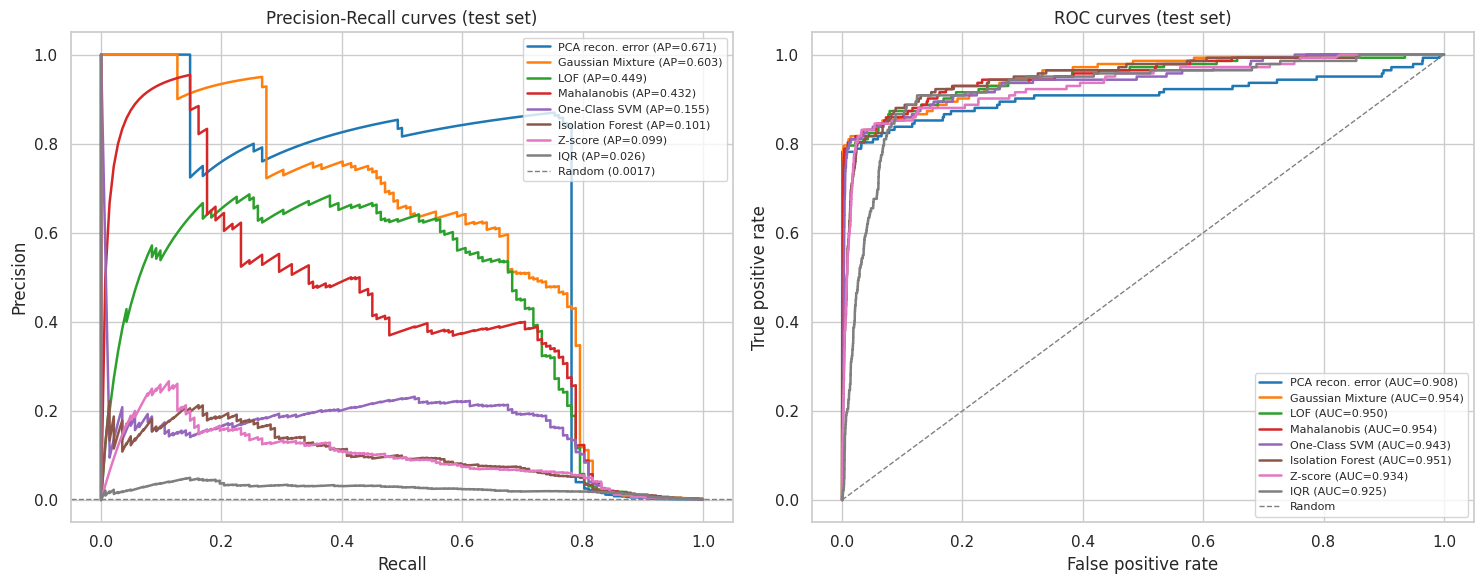

In [38]:
from sklearn.metrics import precision_recall_curve, roc_curve
import matplotlib.pyplot as plt

order = final_tbl["Method"].tolist()
cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

for i, name in enumerate(order):
    s = final_scores[name]
    p, r, _ = precision_recall_curve(y_test, s)
    fpr, tpr, _ = roc_curve(y_test, s)
    ax[0].plot(r, p, color=cmap(i), lw=1.8, label=f"{name} (AP={average_precision_score(y_test, s):.3f})")
    ax[1].plot(fpr, tpr, color=cmap(i), lw=1.8, label=f"{name} (AUC={roc_auc_score(y_test, s):.3f})")

ax[0].axhline(y_test.mean(), color="gray", ls="--", lw=1, label="Random (%.4f)" % y_test.mean())
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision")
ax[0].set_title("Precision-Recall curves (test set)"); ax[0].legend(fontsize=8)

ax[1].plot([0, 1], [0, 1], color="gray", ls="--", lw=1, label="Random")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curves (test set)"); ax[1].legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig("pr_roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

In [39]:
B = 300
rng = np.random.RandomState(SEED)
pos = np.where(y_test == 1)[0]
neg = np.where(y_test == 0)[0]
names = list(final_scores.keys())
boot = {n: np.empty(B) for n in names}

t0 = time.time()
for b in range(B):
    idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
    yb = y_test[idx]
    for n in names:
        boot[n][b] = average_precision_score(yb, final_scores[n][idx])
print("Bootstrap time: %.0f s\n" % (time.time() - t0))

ci = pd.DataFrame({
    "Method": names,
    "AUPRC": [average_precision_score(y_test, final_scores[n]) for n in names],
    "CI_low (2.5%)": [np.percentile(boot[n], 2.5) for n in names],
    "CI_high (97.5%)": [np.percentile(boot[n], 97.5) for n in names],
}).sort_values("AUPRC", ascending=False).reset_index(drop=True)
print(ci.round(4).to_string(index=False))

print("\nPaired comparisons (share of resamples where the first method wins):")
for a, b_ in [("PCA recon. error", "Gaussian Mixture"),
              ("Gaussian Mixture", "LOF"),
              ("LOF", "Mahalanobis")]:
    print(f"  {a} > {b_}: {(boot[a] > boot[b_]).mean():.2f}")

Bootstrap time: 42 s

          Method  AUPRC  CI_low (2.5%)  CI_high (97.5%)
PCA recon. error 0.6706         0.5931           0.7583
Gaussian Mixture 0.6030         0.5263           0.6893
             LOF 0.4495         0.3760           0.5588
     Mahalanobis 0.4319         0.3528           0.5257
   One-Class SVM 0.1545         0.1275           0.1927
Isolation Forest 0.1011         0.0762           0.1368
         Z-score 0.0993         0.0770           0.1373
             IQR 0.0257         0.0210           0.0334

Paired comparisons (share of resamples where the first method wins):
  PCA recon. error > Gaussian Mixture: 1.00
  Gaussian Mixture > LOF: 1.00
  LOF > Mahalanobis: 0.75


In [40]:
# Milestone 7(c)

In [41]:
import time
from sklearn.covariance import EmpiricalCovariance
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import LocalOutlierFactor

val_s, test_s = {}, {}
t0 = time.time()

# Mahalanobis
emp_v = EmpiricalCovariance().fit(X_fit_normal)
val_s["Mahalanobis"], test_s["Mahalanobis"] = emp_v.mahalanobis(X_val), emp_v.mahalanobis(X_test)

# PCA reconstruction error
pca_t = PCA(n_components=K_PCA).fit(X_fit_normal)
rec = lambda X: ((X - pca_t.inverse_transform(pca_t.transform(X))) ** 2).sum(axis=1)
val_s["PCA recon. error"], test_s["PCA recon. error"] = rec(X_val), rec(X_test)

# Gaussian Mixture
gmm_t = GaussianMixture(n_components=K_GMM, covariance_type="full", random_state=SEED).fit(X_fit_normal)
val_s["Gaussian Mixture"], test_s["Gaussian Mixture"] = -gmm_t.score_samples(X_val), -gmm_t.score_samples(X_test)

# LOF on a 20k subsample of the fit-normal data
rng = np.random.RandomState(SEED)
sub = X_fit_normal[rng.choice(len(X_fit_normal), 20000, replace=False)]
lof_t = LocalOutlierFactor(n_neighbors=20, novelty=True, n_jobs=-1).fit(sub)
val_s["LOF"], test_s["LOF"] = -lof_t.score_samples(X_val), -lof_t.score_samples(X_test)

print("Done in %.0f s\n" % (time.time() - t0))
for n in val_s:
    print(f"{n:<18} val AUPRC = {average_precision_score(y_val, val_s[n]):.4f} | "
          f"test AUPRC = {average_precision_score(y_test, test_s[n]):.4f}")

Done in 38 s

Mahalanobis        val AUPRC = 0.4908 | test AUPRC = 0.4315
PCA recon. error   val AUPRC = 0.6960 | test AUPRC = 0.6707
Gaussian Mixture   val AUPRC = 0.6674 | test AUPRC = 0.5597
LOF                val AUPRC = 0.6066 | test AUPRC = 0.4890


          Method  Val F1  Test precision  Test recall  Test F1  TP  FP  FN
PCA recon. error  0.8350          0.8520       0.7680   0.8070 109  19  33
Gaussian Mixture  0.6850          0.6560       0.5770   0.6140  82  43  60
             LOF  0.6950          0.6150       0.5850   0.5990  83  52  59
     Mahalanobis  0.5390          0.5080       0.4300   0.4660  61  59  81

Test set: 142 frauds, 85118 transactions


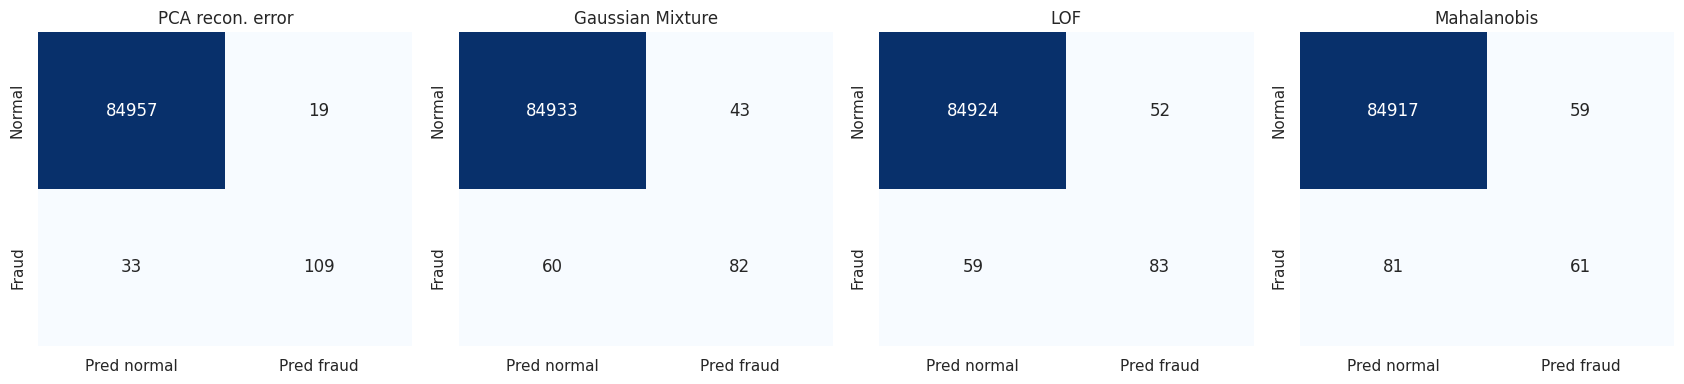

In [42]:
from sklearn.metrics import precision_recall_curve, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

rows, cms = [], {}
for name in val_s:
    p, r, t = precision_recall_curve(y_val, val_s[name])
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    i = int(np.argmax(f1))
    thr, val_f1 = t[i], f1[i]

    pred = test_s[name] >= thr
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    prec = tp / max(tp + fp, 1); rec_ = tp / (tp + fn)
    f1_test = 2 * prec * rec_ / max(prec + rec_, 1e-12)
    cms[name] = np.array([[tn, fp], [fn, tp]])
    rows.append((name, val_f1, prec, rec_, f1_test, int(tp), int(fp), int(fn)))

res = pd.DataFrame(rows, columns=["Method", "Val F1", "Test precision", "Test recall",
                                  "Test F1", "TP", "FP", "FN"])
res = res.sort_values("Test F1", ascending=False).reset_index(drop=True)
print(res.round(3).to_string(index=False))
print("\nTest set: %d frauds, %d transactions" % (y_test.sum(), len(y_test)))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, name in zip(axes, res["Method"]):
    sns.heatmap(cms[name], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred normal", "Pred fraud"], yticklabels=["Normal", "Fraud"])
    ax.set_title(name)
plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

In [43]:
# Milestone 8

In [44]:
import pandas as pd

types = {"Z-score": "Statistical baseline", "IQR": "Statistical baseline",
         "Mahalanobis": "Statistical baseline"}

master = (final_tbl
          .merge(ci[["Method", "CI_low (2.5%)", "CI_high (97.5%)"]], on="Method")
          .rename(columns={"CI_low (2.5%)": "AUPRC CI low", "CI_high (97.5%)": "AUPRC CI high"})
          .merge(res[["Method", "Test precision", "Test recall", "Test F1", "TP", "FP", "FN"]],
                 on="Method", how="left"))
master.insert(1, "Type", master["Method"].map(types).fillna("ML detector"))
for c in ["TP", "FP", "FN"]:
    master[c] = master[c].map(lambda v: "-" if pd.isna(v) else str(int(v)))
master = master.sort_values("AUPRC", ascending=False).reset_index(drop=True)

print(master.round(3).to_string(index=False, na_rep="-"))
print("\nNote: ROC-AUC/AUPRC columns come from models fit on the full training set (Cell 7.4).")
print("Precision/recall/F1/TP/FP/FN come from models refit on 75% of the training data (Cell 7.7),")
print("so the AUPRC of GMM and LOF differs slightly between the two sources.")
master.to_csv("final_results.csv", index=False)

          Method                 Type  ROC-AUC  AUPRC  AUPRC CI low  AUPRC CI high  Test precision  Test recall  Test F1  TP FP FN
PCA recon. error          ML detector   0.9080 0.6710        0.5930         0.7580          0.8520       0.7680   0.8070 109 19 33
Gaussian Mixture          ML detector   0.9540 0.6030        0.5260         0.6890          0.6560       0.5770   0.6140  82 43 60
             LOF          ML detector   0.9500 0.4490        0.3760         0.5590          0.6150       0.5850   0.5990  83 52 59
     Mahalanobis Statistical baseline   0.9540 0.4320        0.3530         0.5260          0.5080       0.4300   0.4660  61 59 81
   One-Class SVM          ML detector   0.9430 0.1550        0.1270         0.1930               -            -        -   -  -  -
Isolation Forest          ML detector   0.9510 0.1010        0.0760         0.1370               -            -        -   -  -  -
         Z-score Statistical baseline   0.9340 0.0990        0.0770         0.1370 

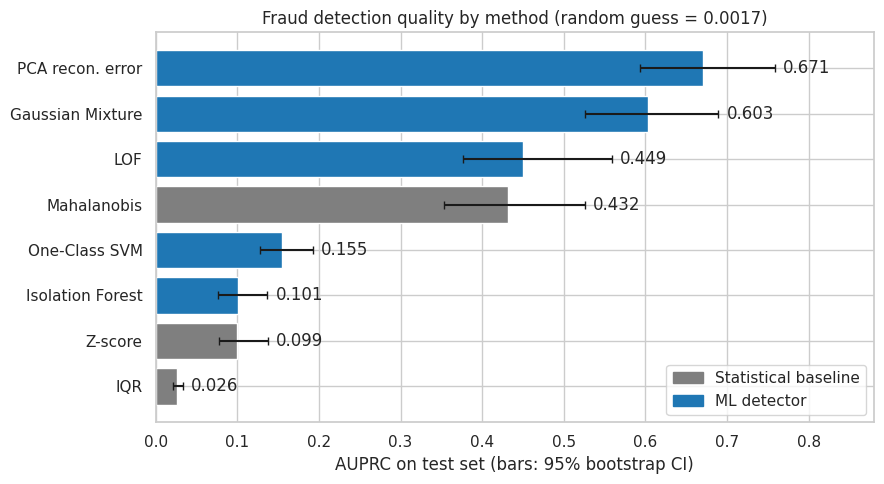

In [45]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

m = master.sort_values("AUPRC")                       # ascending, so the best method ends up on top
err_low  = (m["AUPRC"] - m["AUPRC CI low"]).clip(lower=0).values
err_high = (m["AUPRC CI high"] - m["AUPRC"]).clip(lower=0).values
colors = m["Type"].map({"Statistical baseline": "tab:gray", "ML detector": "tab:blue"}).values

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(m["Method"].values, m["AUPRC"].values, xerr=[err_low, err_high], color=colors, capsize=3)
for i, (v, hi) in enumerate(zip(m["AUPRC"].values, m["AUPRC CI high"].values)):
    ax.text(hi + 0.01, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 0.88)
ax.set_xlabel("AUPRC on test set (bars: 95% bootstrap CI)")
ax.set_title("Fraud detection quality by method (random guess = %.4f)" % y_test.mean())
ax.legend(handles=[Patch(color="tab:gray", label="Statistical baseline"),
                   Patch(color="tab:blue", label="ML detector")], loc="lower right")
plt.tight_layout()
plt.savefig("auprc_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

In [46]:
from sklearn.metrics import precision_recall_curve

# Rebuild the alert decisions exactly as in Cell 7.8 (same thresholds, from validation)
preds = {}
for name in val_s:
    p, r, t = precision_recall_curve(y_val, val_s[name])
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    thr = t[int(np.argmax(f1))]
    preds[name] = test_s[name] >= thr
    print(f"{name:<18} TP = {int((preds[name] & (y_test == 1)).sum())}   (must match Cell 7.8)")

fraud_idx = np.where(y_test == 1)[0]
caught = pd.DataFrame({n: preds[n][fraud_idx] for n in preds})     # one row per test fraud
n_caught = caught.sum(axis=1)

print("\nFrauds caught by exactly k of the 4 detectors:")
for k in range(5):
    print(f"  k = {k}: {int((n_caught == k).sum())}")

pca_missed = ~caught["PCA recon. error"]
others = [c for c in caught.columns if c != "PCA recon. error"]
rescued = int(caught.loc[pca_missed, others].any(axis=1).sum())
print(f"\nPCA misses {int(pca_missed.sum())} frauds; {rescued} of them are caught by at least one other detector")

# Exploratory: raise an alert if ANY of the four fires (thresholds fixed from validation, nothing tuned on test)
any_alert = np.column_stack(list(preds.values())).any(axis=1)
tp_u = int((any_alert & (y_test == 1)).sum()); fp_u = int((any_alert & (y_test == 0)).sum())
print(f"\nOR of all four: TP = {tp_u}, FP = {fp_u}, recall = {tp_u / y_test.sum():.3f}, "
      f"precision = {tp_u / (tp_u + fp_u):.3f}")

# How normal do the PCA-missed frauds look?
s_pca = test_s["PCA recon. error"]
normal_sorted = np.sort(s_pca[y_test == 0])
pct = np.searchsorted(normal_sorted, s_pca[fraud_idx][pca_missed.values]) / len(normal_sorted) * 100
print("\nPCA-missed frauds: median PCA score sits at the %.1fth percentile of normal transactions" % np.median(pct))

amt = np.expm1(X_test_raw["Amount"].values)[fraud_idx]
cp = caught["PCA recon. error"].values
print("Median Amount of frauds caught by PCA: %.2f | missed by PCA: %.2f" % (np.median(amt[cp]), np.median(amt[~cp])))

Mahalanobis        TP = 61   (must match Cell 7.8)
PCA recon. error   TP = 109   (must match Cell 7.8)
Gaussian Mixture   TP = 82   (must match Cell 7.8)
LOF                TP = 83   (must match Cell 7.8)

Frauds caught by exactly k of the 4 detectors:
  k = 0: 32
  k = 1: 15
  k = 2: 18
  k = 3: 24
  k = 4: 53

PCA misses 33 frauds; 1 of them are caught by at least one other detector

OR of all four: TP = 110, FP = 85, recall = 0.775, precision = 0.564

PCA-missed frauds: median PCA score sits at the 78.5th percentile of normal transactions
Median Amount of frauds caught by PCA: 33.59 | missed by PCA: 1.79


In [47]:
import os
for f in ["pr_roc_curves.png", "confusion_matrices.png", "auprc_comparison.png", "final_results.csv"]:
    print(f, "->", "OK (%d KB)" % (os.path.getsize(f) / 1024) if os.path.exists(f) else "MISSING")

pr_roc_curves.png -> OK (343 KB)
confusion_matrices.png -> OK (58 KB)
auprc_comparison.png -> OK (111 KB)
final_results.csv -> OK (1 KB)


In [48]:
# Milestone 11(a)

In [49]:
needed = ["final_scores", "final_tbl", "ci", "res", "test_s", "val_s", "y_test", "y_val", "y_train",
          "sep", "last", "boot", "caught", "n_caught", "preds", "pca_missed", "rescued", "tp_u", "fp_u",
          "amt", "cp", "scaler", "pca_t", "gmm_t", "emp_v", "lof_t", "feat", "df_clean",
          "X_test_raw", "K_PCA", "K_GMM"]
missing = [v for v in needed if v not in globals()]
print("Missing variables:", missing if missing else "none")

import plotly, ipywidgets
print("plotly", plotly.__version__, "| ipywidgets", ipywidgets.__version__)

Missing variables: none
plotly 5.24.1 | ipywidgets 7.7.1


In [50]:
from google.colab import output
try:
    output.enable_custom_widget_manager()
except Exception as e:
    print("Custom widget manager not available (usually fine):", e)

import plotly.io as pio
pio.renderers.default = "colab"

from IPython.display import display, HTML, clear_output
import ipywidgets as W
import plotly.graph_objects as go
import numpy as np, pandas as pd

CSS = """
<style>
.al-root{--jp-widgets-label-color:#c9ced9;--jp-widgets-color:#e6e8ee;
  --jp-widgets-input-background-color:#14171f;--jp-widgets-input-color:#e6e8ee;
  --jp-widgets-input-border-color:#2b3144;--jp-widgets-font-size:13px;
  background:#0d0f14;color:#e6e8ee;font-family:Inter,'Segoe UI',Arial,sans-serif;
  padding:16px;border-radius:14px;}
.al-brand{font-size:19px;font-weight:700;margin-bottom:2px}
.al-brandsub{font-size:11px;color:#6f778a;margin-bottom:14px}
.al-title{font-size:26px;font-weight:700;margin:0}
.al-sub{color:#8b93a7;font-size:13px;margin:2px 0 14px}
.al-kpis{display:flex;gap:12px;flex-wrap:wrap;margin-bottom:6px}
.al-kpi{flex:1;min-width:150px;background:#14171f;border:1px solid #232838;border-radius:12px;padding:14px 16px}
.al-kl{color:#8b93a7;font-size:11px;text-transform:uppercase;letter-spacing:.05em}
.al-kv{font-size:28px;font-weight:700;line-height:1.3}
.al-ks{font-size:12px;color:#8b93a7}
.al-ks.good{color:#3ecf8e}.al-ks.warn{color:#f5b942}
.al-sec{font-size:15px;font-weight:600;margin:16px 0 8px}
table.al-t{width:100%;border-collapse:collapse;font-size:13px;background:#11141b;border-radius:10px;overflow:hidden}
table.al-t th{text-align:left;color:#8b93a7;font-weight:500;font-size:11px;text-transform:uppercase;
  letter-spacing:.05em;padding:10px 8px;background:#0f1218;border-bottom:1px solid #232838}
table.al-t td{padding:11px 8px;border-bottom:1px solid #1c2030;color:#e6e8ee}
.al-bd{padding:2px 9px;border-radius:6px;font-size:11px;font-weight:600;border:1px solid}
.al-bd.ml{color:#8fa0ff;border-color:#3a4180;background:#1a1e3a}
.al-bd.st{color:#b0b6c4;border-color:#3a3f4d;background:#1b1e27}
.al-bw{display:inline-block;width:100px;height:7px;background:#222736;border-radius:4px;margin-right:8px;overflow:hidden;vertical-align:middle}
.al-b{display:block;height:100%;background:linear-gradient(90deg,#5b6cff,#9b7bff)}
.al-dim{color:#4d5466}.al-ci{color:#6f778a;font-size:11px;margin-left:6px}
.al-nav .widget-toggle-buttons{width:100%}
.al-nav .widget-toggle-buttons button{width:100%!important;text-align:left;background:transparent!important;
  color:#c9ced9!important;border:none!important;box-shadow:none!important;margin:2px 0!important;
  padding:0 12px!important;border-radius:8px!important}
.al-nav .widget-toggle-buttons button.mod-active{background:#232846!important;color:#fff!important}
.al-nav .widget-toggle-buttons button:hover{background:#1a1e30!important}
</style>
"""
display(HTML(CSS))
print("Theme loaded.")

Theme loaded.


In [51]:
# ---------- data for the dashboard (built from your existing variables) ----------
n_test, n_pos = len(y_test), int(y_test.sum())
fraud_rate = n_pos / n_test
types = {"Z-score": "Statistical baseline", "IQR": "Statistical baseline", "Mahalanobis": "Statistical baseline"}

M = (final_tbl.merge(ci[["Method", "CI_low (2.5%)", "CI_high (97.5%)"]], on="Method")
              .merge(res[["Method", "Test precision", "Test recall", "Test F1", "TP", "FP", "FN"]],
                     on="Method", how="left"))
M["Type"] = M["Method"].map(types).fillna("ML detector")
M = M.sort_values("AUPRC", ascending=False).reset_index(drop=True)

best = M.iloc[0]
top_op = M.dropna(subset=["Test F1"]).sort_values("Test F1", ascending=False).iloc[0]

# ---------- helpers ----------
def kpi(label, value, sub, tone=""):
    return (f'<div class="al-kpi"><div class="al-kl">{label}</div><div class="al-kv">{value}</div>'
            f'<div class="al-ks {tone}">{sub}</div></div>')

def page_header(title, sub):
    return W.HTML(f'<p class="al-title">{title}</p><p class="al-sub">{sub}</p>')

def leaderboard_html(df):
    head = ("<table class='al-t'><tr><th>#</th><th>Method</th><th>Type</th><th>AUPRC (95% CI)</th><th>ROC-AUC</th>"
            "<th>Precision</th><th>Recall</th><th>F1</th><th>Alerts</th></tr>")
    rows, dash = "", "<span class='al-dim'>-</span>"
    mx = M["AUPRC"].max()
    for i, (_, r) in enumerate(df.iterrows(), 1):
        kind = "ml" if r["Type"] == "ML detector" else "st"
        has = pd.notna(r["Test F1"])
        first = (f"<tr><td class='al-dim'>{i}</td><td><b>{r['Method']}</b></td>"
                 f"<td><span class='al-bd {kind}'>{r['Type']}</span></td>"
                 f"<td><span class='al-bw'><span class='al-b' style='width:{r['AUPRC']/mx*100:.0f}%'></span></span>"
                 f"<b>{r['AUPRC']:.3f}</b><span class='al-ci'>[{r['CI_low (2.5%)']:.2f}-{r['CI_high (97.5%)']:.2f}]</span></td>"
                 f"<td>{r['ROC-AUC']:.3f}</td>")
        if has:
            rows += first + (f"<td>{r['Test precision']:.3f}</td><td>{r['Test recall']:.3f}</td>"
                             f"<td>{r['Test F1']:.3f}</td><td>{int(r['TP'] + r['FP'])}</td></tr>")
        else:
            rows += first + f"<td>{dash}</td><td>{dash}</td><td>{dash}</td><td>{dash}</td></tr>"
    return head + rows + "</table>"

def dark(fig, h=360):
    fig.update_layout(template="plotly_dark", paper_bgcolor="rgba(0,0,0,0)", plot_bgcolor="rgba(0,0,0,0)",
                      height=h, margin=dict(l=10, r=10, t=45, b=10), font=dict(color="#c9ced9"),
                      legend=dict(orientation="h", y=-0.15))
    fig.update_xaxes(gridcolor="#242836"); fig.update_yaxes(gridcolor="#242836")
    return fig

# ---------- Overview page ----------
dd_type = W.Dropdown(options=["All methods", "ML detector", "Statistical baseline"], description="Show:",
                     layout=W.Layout(width="260px"))
dd_sort = W.Dropdown(options=["AUPRC", "ROC-AUC", "Test F1"], description="Sort by:",
                     layout=W.Layout(width="260px"))
out_table, out_chart = W.Output(), W.Output()

def refresh_overview(_=None):
    df = M if dd_type.value == "All methods" else M[M["Type"] == dd_type.value]
    df = df.sort_values(dd_sort.value, ascending=False, na_position="last")
    with out_table:
        clear_output(wait=True); display(HTML(leaderboard_html(df)))
    s = df.sort_values("AUPRC")
    fig = go.Figure(go.Bar(
        x=s["AUPRC"], y=s["Method"], orientation="h",
        marker_color=["#7c8cff" if t == "ML detector" else "#8b93a7" for t in s["Type"]],
        error_x=dict(type="data", symmetric=False,
                     array=(s["CI_high (97.5%)"] - s["AUPRC"]).clip(lower=0),
                     arrayminus=(s["AUPRC"] - s["CI_low (2.5%)"]).clip(lower=0), color="#9aa3b5"),
        hovertemplate="%{y}: AUPRC %{x:.3f}<extra></extra>"))
    fig.update_layout(title=f"AUPRC by method (random guess = {fraud_rate:.4f})")
    fig.update_xaxes(range=[0, 0.85])
    with out_chart:
        clear_output(wait=True); dark(fig).show()

dd_type.observe(refresh_overview, names="value")
dd_sort.observe(refresh_overview, names="value")

kpis = W.HTML('<div class="al-kpis">' + "".join([
    kpi("Test transactions", f"{n_test:,}", "never used for fitting"),
    kpi("Confirmed frauds", f"{n_pos}", f"{fraud_rate*100:.3f}% of test", "warn"),
    kpi("Best AUPRC", f"{best['AUPRC']:.3f}", f"{best['Method']} · {best['AUPRC']/fraud_rate:,.0f}x random", "good"),
    kpi("Precision", f"{top_op['Test precision']*100:.1f}%", f"{top_op['Method']} at tuned threshold"),
    kpi("Recall", f"{top_op['Test recall']*100:.1f}%", f"{int(top_op['TP'])} of {n_pos} frauds caught"),
]) + "</div>")

overview = W.VBox([
    page_header("Fraud Detection Overview",
                f"Held-out test set · {n_test:,} transactions · {n_pos} frauds ({fraud_rate*100:.3f}%)"),
    kpis,
    W.HTML('<div class="al-sec">Model leaderboard</div>'),
    W.HBox([dd_type, dd_sort]), out_table,
    W.HTML("<div class='al-ks' style='margin:6px 0 10px'>AUPRC and ROC-AUC: full-train models. Precision, recall, F1, "
           "alerts: models refit on 75% of train, threshold chosen on validation data, applied once to test.</div>"),
    out_chart,
])

# ---------- navigation and page switching ----------
PAGES = ["Overview", "Curves", "Threshold Explorer", "Score Distributions",
         "Why It Works", "Error Analysis", "Live Scoring", "Method & Limitations"]
pages = {p: overview if p == "Overview" else
         W.VBox([page_header(p, "Built in a later step."),
                 W.HTML("<div class='al-ks'>Placeholder: this page is coming in 11b to 11d.</div>")])
         for p in PAGES}

nav = W.ToggleButtons(options=PAGES, value="Overview", orientation="vertical",
                      layout=W.Layout(width="100%"))
nav.style.button_width = "190px"
content = W.VBox([pages["Overview"]], layout=W.Layout(flex="1", min_width="0"))

def go_page(change):
    content.children = [pages[change["new"]]]
nav.observe(go_page, names="value")

sidebar = W.VBox([W.HTML('<div class="al-brand">🛡️ Anomaly Lens</div>'
                         '<div class="al-brandsub">Statistical ML · Fraud detection</div>'),
                  nav,
                  W.HTML('<div class="al-brandsub" style="margin-top:16px">Data: ULB credit-card fraud<br>'
                         'Detectors fit on normal<br>transactions only</div>')],
                 layout=W.Layout(width="210px", margin="0 18px 0 0"))
sidebar.add_class("al-nav")

root = W.HBox([sidebar, content])
root.add_class("al-root")
display(root)
refresh_overview()

In [52]:
# Re-uses CSS (from Cell 11.2), nav, sidebar, content, refresh_overview (from 11.3)
if "CSS" not in globals():
    raise RuntimeError("Cell 11.2 has not been run in this session. Run it first, then re-run this cell.")

style_widget = W.HTML(CSS)                      # CSS now lives inside the same widget tree
root = W.VBox([style_widget, W.HBox([sidebar, content])])
root.add_class("al-root")

clear_output(wait=True)
display(root)
refresh_overview()

In [53]:
# Milestone 11(b)

In [54]:
from sklearn.metrics import precision_recall_curve, roc_curve, average_precision_score, roc_auc_score

PALETTE = ["#7c8cff", "#3ecf8e", "#f5b942", "#ef5b5b", "#c084fc", "#38bdf8", "#fb923c", "#94a3b8"]
order = M["Method"].tolist()
color_of = {m: PALETTE[i % len(PALETTE)] for i, m in enumerate(order)}

# ============================ CURVES PAGE ============================
checks = {m: W.Checkbox(value=(m in order[:4]), description=m, indent=False,
                        layout=W.Layout(width="190px")) for m in order}
out_pr, out_roc = W.Output(), W.Output()

def draw_curves(_=None):
    sel = [m for m in order if checks[m].value]
    f1 = go.Figure(); f2 = go.Figure()
    for m in sel:
        s = final_scores[m]
        p, r, _ = precision_recall_curve(y_test, s)
        fpr, tpr, _ = roc_curve(y_test, s)
        f1.add_scatter(x=r, y=p, mode="lines", name=f"{m} (AP={average_precision_score(y_test, s):.3f})",
                       line=dict(color=color_of[m], width=2))
        f2.add_scatter(x=fpr, y=tpr, mode="lines", name=f"{m} (AUC={roc_auc_score(y_test, s):.3f})",
                       line=dict(color=color_of[m], width=2))
    f1.add_hline(y=fraud_rate, line_dash="dash", line_color="#6f778a", annotation_text="random")
    f2.add_scatter(x=[0, 1], y=[0, 1], mode="lines", name="random",
                   line=dict(color="#6f778a", dash="dash"))
    f1.update_layout(title="Precision-Recall (test set)", xaxis_title="Recall", yaxis_title="Precision")
    f2.update_layout(title="ROC (test set)", xaxis_title="False positive rate", yaxis_title="True positive rate")
    with out_pr:
        clear_output(wait=True); dark(f1, 420).show()
    with out_roc:
        clear_output(wait=True); dark(f2, 420).show()

for c in checks.values():
    c.observe(draw_curves, names="value")

curves_page = W.VBox([
    page_header("Curves", "Tick methods to compare. PR is the honest view at a 0.17% fraud rate; ROC looks good for everything."),
    W.GridBox(list(checks.values()), layout=W.Layout(grid_template_columns="repeat(4, 200px)")),
    out_pr, out_roc,
])

# ============================ THRESHOLD EXPLORER ============================
OP = list(test_s.keys())                       # the 4 operating detectors
dd_m = W.Dropdown(options=OP, value="PCA recon. error", description="Method:", layout=W.Layout(width="300px"))
sl = W.IntSlider(min=10, max=600, step=1, value=128, description="Alerts:",
                 continuous_update=False, layout=W.Layout(width="620px"))
out_thr = W.Output()
n_normal = n_test - n_pos
_order_cache = {m: np.argsort(-test_s[m], kind="stable") for m in OP}

def draw_thr(_=None):
    m, N = dd_m.value, sl.value
    top = _order_cache[m][:N]
    tp = int(y_test[top].sum()); fp = N - tp; fn = n_pos - tp; tn = n_normal - fp
    prec = tp / N; rec = tp / n_pos; f1 = 2 * prec * rec / max(prec + rec, 1e-12)
    chosen = int(preds[m].sum())

    cm = go.Figure(go.Heatmap(
        z=[[tn, fp], [fn, tp]], x=["Pred normal", "Pred fraud"], y=["Normal", "Fraud"],
        text=[[f"{tn:,}", f"{fp:,}"], [f"{fn:,}", f"{tp:,}"]], texttemplate="%{text}",
        textfont=dict(size=18), colorscale=[[0, "#14171f"], [1, "#3b4cc0"]], showscale=False,
        hoverinfo="skip"))
    cm.update_yaxes(autorange="reversed")
    cm.update_layout(title="Confusion matrix at this threshold")

    cards = ('<div class="al-kpis">' + "".join([
        kpi("Alerts raised", f"{N}", f"validation-chosen: {chosen}"),
        kpi("Frauds caught", f"{tp}", f"of {n_pos}", "good"),
        kpi("False alarms", f"{fp}", f"{fp / n_normal * 100:.3f}% of normal", "warn"),
        kpi("Precision", f"{prec * 100:.1f}%", "alerts that are real"),
        kpi("Recall", f"{rec * 100:.1f}%", "frauds caught"),
        kpi("F1", f"{f1:.3f}", "balance of both"),
    ]) + "</div>")
    with out_thr:
        clear_output(wait=True)
        display(HTML(cards)); dark(cm, 330).show()

dd_m.observe(draw_thr, names="value"); sl.observe(draw_thr, names="value")

def reset_slider(_):
    sl.value = int(preds[dd_m.value].sum())
btn_reset = W.Button(description="Jump to validation-chosen threshold", button_style="info",
                     layout=W.Layout(width="290px"))
btn_reset.on_click(reset_slider)

thr_page = W.VBox([
    page_header("Threshold Explorer", "Drag the slider: more alerts catch more frauds but raise more false alarms."),
    W.HBox([dd_m, btn_reset]), sl,
    W.HTML("<div class='al-ks' style='margin:4px 0 8px'>Scores come from the models refit on 75% of train (Cell 7.7), "
           "evaluated on the held-out test set. Alerts = the N highest-scoring test transactions.</div>"),
    out_thr,
])

# ============================ wire into navigation ============================
pages["Curves"] = curves_page
pages["Threshold Explorer"] = thr_page
content.children = [pages[nav.value]]
draw_curves(); draw_thr()
print("Curves and Threshold Explorer pages are live. Click them in the sidebar.")

Curves and Threshold Explorer pages are live. Click them in the sidebar.


In [54]:
# Milestone 10

In [55]:
needed = ["final_scores", "final_tbl", "ci", "res", "test_s", "val_s", "y_test", "y_val", "y_train",
          "sep", "last", "boot", "caught", "n_caught", "preds", "pca_missed", "rescued", "tp_u", "fp_u",
          "amt", "cp", "scaler", "pca_t", "gmm_t", "emp_v", "lof_t", "feat", "df", "df_clean",
          "X_test_raw", "K_PCA", "K_GMM"]
missing = [v for v in needed if v not in globals()]
print("Missing variables:", missing if missing else "none")

Missing variables: none


In [56]:
import json, os
import numpy as np, pandas as pd

n_test = len(y_test); n_pos = int(y_test.sum()); n_neg = n_test - n_pos
grid = np.unique(np.concatenate([
    np.arange(1, 301),
    np.round(np.logspace(np.log10(300), np.log10(n_test), 250)).astype(int)]))

def sweep(score):
    order = np.argsort(-score, kind="stable")
    tp = np.cumsum(y_test[order])[grid - 1]
    return tp.astype(int).tolist(), (grid - tp).astype(int).tolist()

def histo(score, bins=40):
    t = np.log1p(score - score.min())
    edges = np.linspace(t.min(), t.max(), bins + 1)
    hn, _ = np.histogram(t[y_test == 0], edges)
    hf, _ = np.histogram(t[y_test == 1], edges)
    return {"edges": np.round(edges, 4).tolist(),
            "normal": np.round(hn / hn.sum(), 5).tolist(),
            "fraud": np.round(hf / hf.sum(), 5).tolist()}

op_methods = list(test_s.keys())
chosen_alerts = {n: int(preds[n].sum()) for n in op_methods}

ci_i, res_i = ci.set_index("Method"), res.set_index("Method")
types = {"Z-score": "Statistical baseline", "IQR": "Statistical baseline",
         "Mahalanobis": "Statistical baseline"}
metrics = []
for _, r in final_tbl.iterrows():
    m = r["Method"]
    row = {"method": m, "type": types.get(m, "ML detector"),
           "roc_auc": float(r["ROC-AUC"]), "auprc": float(r["AUPRC"]),
           "ci_low": float(ci_i.loc[m, "CI_low (2.5%)"]),
           "ci_high": float(ci_i.loc[m, "CI_high (97.5%)"])}
    if m in res_i.index:
        for src, dst in [("Test precision", "precision"), ("Test recall", "recall"),
                         ("Test F1", "f1"), ("Val F1", "val_f1"),
                         ("TP", "tp"), ("FP", "fp"), ("FN", "fn")]:
            v = res_i.loc[m, src]
            row[dst] = int(v) if dst in ("tp", "fp", "fn") else float(v)
    metrics.append(row)

pairs = [("PCA recon. error", "Gaussian Mixture"), ("Gaussian Mixture", "LOF"), ("LOF", "Mahalanobis")]
data = {
    "meta": {"n_test": n_test, "n_test_fraud": n_pos, "n_test_normal": n_neg,
             "fraud_rate": n_pos / n_test, "K_PCA": int(K_PCA), "K_GMM": int(K_GMM),
             "raw_rows": int(len(df)), "raw_fraud": int(df["Class"].sum()),
             "clean_rows": int(len(df_clean)), "clean_fraud": int(df_clean["Class"].sum()),
             "train_rows": int(len(y_train)), "val_frauds": int(y_val.sum())},
    "grid": grid.tolist(),
    "curves": {n: dict(zip(["tp", "fp"], sweep(final_scores[n]))) for n in final_scores},
    "operating": {n: {**dict(zip(["tp", "fp"], sweep(test_s[n]))),
                      "chosen_alerts": chosen_alerts[n], "hist": histo(test_s[n])}
                  for n in op_methods},
    "metrics": metrics,
    "features": {
        "ks_top": [{"feature": r.feature, "ks": float(r.KS_stat), "corr": float(r.corr_with_Class)}
                   for r in sep.head(10).itertuples()],
        "pc_last_loadings": [{"feature": f, "loading": float(v)}
                             for f, v in last.reindex(last.abs().sort_values(ascending=False).index).head(8).items()],
    },
    "errors": {
        "caught_by_k": [int((n_caught == k).sum()) for k in range(5)],
        "pca_missed": int(pca_missed.sum()), "pca_missed_rescued": int(rescued),
        "or_tp": int(tp_u), "or_fp": int(fp_u),
        "amount_caught_median": float(np.median(amt[cp])),
        "amount_missed_median": float(np.median(amt[~cp])),
        "log_amount_caught": np.round(np.log1p(amt[cp]), 3).tolist(),
        "log_amount_missed": np.round(np.log1p(amt[~cp]), 3).tolist(),
    },
    "paired": [{"a": a, "b": b, "p": float((boot[a] > boot[b]).mean())} for a, b in pairs],
}
with open("dashboard_data.json", "w") as f:
    json.dump(data, f)

print("Saved dashboard_data.json (%.0f KB)" % (os.path.getsize("dashboard_data.json") / 1024))
print("Sanity check (alerts -> TP):")
for n in op_methods:
    j = int(np.where(grid == chosen_alerts[n])[0][0])
    print(f"  {n:<18} alerts = {chosen_alerts[n]:>3} -> TP = {data['operating'][n]['tp'][j]}")

Saved dashboard_data.json (74 KB)
Sanity check (alerts -> TP):
  Mahalanobis        alerts = 120 -> TP = 61
  PCA recon. error   alerts = 128 -> TP = 109
  Gaussian Mixture   alerts = 125 -> TP = 82
  LOF                alerts = 135 -> TP = 83


In [57]:
import os, sys, shutil, joblib
import sklearn, scipy
from sklearn.metrics import precision_recall_curve

os.makedirs("streamlit_app/models", exist_ok=True)
os.makedirs("streamlit_app/data", exist_ok=True)

thresholds = {}
for name in val_s:
    p, r, t = precision_recall_curve(y_val, val_s[name])
    f1 = 2 * p[:-1] * r[:-1] / np.maximum(p[:-1] + r[:-1], 1e-12)
    thresholds[name] = float(t[int(np.argmax(f1))])

bundle = {
    "feature_names": list(feat.columns),
    "scaler": scaler,
    "models": {"Mahalanobis": emp_v, "PCA recon. error": pca_t,
               "Gaussian Mixture": gmm_t, "LOF": lof_t},
    "thresholds": thresholds,
    "K_PCA": int(K_PCA), "K_GMM": int(K_GMM),
    "versions": {"python": sys.version.split()[0], "sklearn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__},
}
joblib.dump(bundle, "streamlit_app/models/bundle.joblib", compress=3)

def score_all(raw_df, b):
    X = raw_df[b["feature_names"]].copy()
    X["Amount"] = np.log1p(X["Amount"])
    Z = b["scaler"].transform(X)
    m = b["models"]; pca = m["PCA recon. error"]
    return {"Mahalanobis": m["Mahalanobis"].mahalanobis(Z),
            "PCA recon. error": ((Z - pca.inverse_transform(pca.transform(Z))) ** 2).sum(axis=1),
            "Gaussian Mixture": -m["Gaussian Mixture"].score_samples(Z),
            "LOF": -m["LOF"].score_samples(Z)}

b2 = joblib.load("streamlit_app/models/bundle.joblib")
new_scores = score_all(df_clean.loc[X_test_raw.index], b2)
print("End-to-end check (reloaded bundle, raw CSV columns -> scores):")
for n in new_scores:
    same = np.allclose(new_scores[n], test_s[n], rtol=1e-6, atol=1e-8)
    flagged = new_scores[n] >= b2["thresholds"][n]
    tp = int((flagged & (y_test == 1)).sum())
    print(f"  {n:<18} scores identical: {same} | alerts: {int(flagged.sum()):>3} "
          f"(notebook: {int(preds[n].sum())}) | TP: {tp}")

rng = np.random.RandomState(42)
pos = X_test_raw.index[y_test == 1]; neg = X_test_raw.index[y_test == 0]
pick = np.concatenate([rng.choice(neg, 4000, replace=False), rng.choice(pos, 60, replace=False)])
df_clean.loc[pick].sample(frac=1, random_state=42).to_csv("streamlit_app/data/demo_transactions.csv", index=False)

shutil.copy("dashboard_data.json", "streamlit_app/data/dashboard_data.json")
shutil.make_archive("streamlit_app", "zip", "streamlit_app")
print("\nPin these versions:", b2["versions"])

from google.colab import files
files.download("streamlit_app.zip")

End-to-end check (reloaded bundle, raw CSV columns -> scores):
  Mahalanobis        scores identical: True | alerts: 120 (notebook: 120) | TP: 61
  PCA recon. error   scores identical: True | alerts: 128 (notebook: 128) | TP: 109
  Gaussian Mixture   scores identical: True | alerts: 125 (notebook: 125) | TP: 82
  LOF                scores identical: True | alerts: 135 (notebook: 135) | TP: 83

Pin these versions: {'python': '3.13.16', 'sklearn': '1.6.1', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3'}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>